# Exploratory Data Analysis (EDA) — Global University Rankings

This notebook performs a complete, corrected exploratory analysis of the global university-rankings dataset (1,000 institutions, 7 sub-indicators + final Score).


1. Imports & visual settings
2. Load data & initial review
3. Identify data-quality issues
4. Clean & prepare the data
5. Descriptive statistics
6. Missing values — pattern analysis & duplicates
7. Distribution analysis
8. Outlier detection
9. Country-level analysis
10. Top universities
11. Correlation analysis
12. Multivariate comparison across countries
13. Conclusion & key findings


## 1. Imports & Visual Settings

In [73]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import missingno as msno

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# --- Color system -----------------------------------------------------------

SEQ_CMAP = sns.color_palette("viridis", as_cmap=True)
FLAT_COLOR = "#4C72B0"
CAT_PALETTE = sns.color_palette("tab10")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.labelsize": 10.5,
    "legend.frameon": False,
})


## 2. Load the Data & Initial Review

The file is saved with a non-UTF-8 encoding, so `encoding='utf-8'` fails; `encoding='latin-1'` reads it correctly.

In [74]:
df = pd.read_csv('Z.csv', encoding='latin-1')

print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
print(f"Columns: {list(df.columns)}")
df.tail()


Rows: 1000, Columns: 12
Columns: ['World Rank', 'Institution', 'Location', 'National Rank', 'Quality\xa0of Education', 'Alumni Employment', 'Quality\xa0of Faculty', 'Research Output', 'Quality Publications', 'Influence', 'Citations', 'Score']


,World Rank,Institution,Location,National Rank,Quality of Education,Alumni Employment,Quality of Faculty,Research Output,Quality Publications,Influence,Citations,Score
995,996,Aga Khan University,Pakistan,3,-,> 1000,-,> 1000,> 1000,464,673,69.80
996,997,University of Calcutta,India,17,353,716,296,798,966,> 1000,> 1000,69.80
997,998,K?chi University,Japan,56,-,> 1000,-,> 1000,> 1000,811,673,69.80
998,999,Soonchunhyang University,South Korea,35,-,> 1000,-,881,> 1000,> 1000,898,69.80
999,1000,Capital Normal University,China,108,-,869,-,923,904,889,> 1000,69.80


In [75]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   World Rank            1000 non-null   int64  
 1   Institution           1000 non-null   object 
 2   Location              1000 non-null   object 
 3   National Rank         1000 non-null   int64  
 4   Quality of Education  1000 non-null   object 
 5   Alumni Employment     1000 non-null   object 
 6   Quality of Faculty    1000 non-null   object 
 7   Research Output       1000 non-null   object 
 8   Quality Publications  1000 non-null   object 
 9   Influence             1000 non-null   object 
 10  Citations             1000 non-null   object 
 11  Score                 1000 non-null   float64
dtypes: float64(1), int64(2), object(9)
memory usage: 93.9+ KB


## 3. Identify Data-Quality Issues

- Some column names contain a non-breaking space (`\xa0`) instead of a regular space.
- Several columns that should be numeric are stored as text because they contain the non-numeric markers `'-'` and `'> 1000'`.

In [76]:
for c in df.columns:
    print(repr(c))


'World Rank'
'Institution'
'Location'
'National Rank'
'Quality\xa0of Education'
'Alumni Employment'
'Quality\xa0of Faculty'
'Research Output'
'Quality Publications'
'Influence'
'Citations'
'Score'


In [77]:
# Fix column names: replace non-breaking space with a regular space
df.columns = [c.replace('\xa0', ' ').strip() for c in df.columns]
print(df.columns.tolist())


['World Rank', 'Institution', 'Location', 'National Rank', 'Quality of Education', 'Alumni Employment', 'Quality of Faculty', 'Research Output', 'Quality Publications', 'Influence', 'Citations', 'Score']


In [78]:
numeric_like_cols = ['Quality of Education', 'Alumni Employment', 'Quality of Faculty',
                      'Research Output', 'Quality Publications', 'Influence', 'Citations']

for c in numeric_like_cols:
    vals = df[c].astype(str).unique()
    non_numeric = sorted({v for v in vals if not v.strip().replace('.', '', 1).isdigit()})
    print(f"{c:25s} -> non-numeric markers: {non_numeric}")


Quality of Education      -> non-numeric markers: ['-']
Alumni Employment         -> non-numeric markers: ['> 1000']
Quality of Faculty        -> non-numeric markers: ['-']
Research Output           -> non-numeric markers: ['> 1000']
Quality Publications      -> non-numeric markers: ['> 1000']
Influence                 -> non-numeric markers: ['> 1000']
Citations                 -> non-numeric markers: ['> 1000']


**Important distinction for later (missing-value strategy):** the non-numeric marker is **not the same** in every column.

- `Quality of Education` and `Quality of Faculty` use `'-'` -- this genuinely means *no data was recorded*.
- `Alumni Employment`, `Research Output`, `Quality Publications`, `Influence`, `Citations` use `'> 1000'` -- this means the value **is known**, it is simply a rank worse than 1000. This is not missing data; it is a right-censored value.

These two cases need different treatment, handled below.

## 4. Clean & Prepare the Data

- `'-'` -> `NaN` (true missing data -- left as `NaN`, **not imputed**; see Section 6 for why).
- `'> 1000'` -> `1001` (a documented, reversible placeholder for "worse than rank 1000").
- All seven columns converted to numeric.

In [79]:
df_clean = df.copy()

for c in numeric_like_cols:
    df_clean[c] = (
        df_clean[c].astype(str).str.strip()
        .replace({'-': np.nan, '> 1000': '1001'})
    )
    df_clean[c] = pd.to_numeric(df_clean[c], errors='coerce')

df_clean.dtypes


World Rank                int64
Institution              object
Location                 object
National Rank             int64
Quality of Education    float64
Alumni Employment         int64
Quality of Faculty      float64
Research Output           int64
Quality Publications      int64
Influence                 int64
Citations                 int64
Score                   float64
dtype: object

In [80]:
df_clean.tail()


,World Rank,Institution,Location,National Rank,Quality of Education,Alumni Employment,Quality of Faculty,Research Output,Quality Publications,Influence,Citations,Score
995,996,Aga Khan University,Pakistan,3,NaN,1001,NaN,1001,1001,464,673,69.80
996,997,University of Calcutta,India,17,353.00,716,296.00,798,966,1001,1001,69.80
997,998,K?chi University,Japan,56,NaN,1001,NaN,1001,1001,811,673,69.80
998,999,Soonchunhyang University,South Korea,35,NaN,1001,NaN,881,1001,1001,898,69.80
999,1000,Capital Normal University,China,108,NaN,869,NaN,923,904,889,1001,69.80


## 5. Descriptive Statistics

In [81]:
df_clean.describe().T


,count,mean,std,min,25%,50%,75%,max
World Rank,"1,000.00",500.50,288.82,1.00,250.75,500.50,750.25,"1,000.00"
National Rank,"1,000.00",40.02,49.23,1.00,6.00,21.00,51.00,213.00
Quality of Education,403.00,323.41,194.08,1.00,151.50,321.00,490.50,666.00
Alumni Employment,"1,000.00",726.53,343.69,1.00,425.75,"1,001.00","1,001.00","1,001.00"
Quality of Faculty,269.00,144.82,88.64,1.00,68.00,140.00,223.00,303.00
Research Output,"1,000.00",508.45,300.08,1.00,250.75,500.50,754.25,"1,001.00"
Quality Publications,"1,000.00",503.00,292.85,1.00,250.75,500.50,750.25,"1,001.00"
Influence,"1,000.00",529.16,322.42,1.00,250.75,502.50,814.75,"1,001.00"
Citations,"1,000.00",501.16,308.87,1.00,240.00,460.00,673.00,"1,001.00"
Score,"1,000.00",75.03,4.67,69.80,71.50,73.75,77.30,100.00


In [82]:
df_clean.describe(include='object').T


,count,unique,top,freq
Institution,1000,1000,Harvard University,1
Location,1000,61,USA,213


## 6. Missing Values -- Pattern Analysis & Duplicates

Counting missing values is not enough on its own -- the important question is *why* they are missing, because that determines what (if anything) should be done about them. This section:

1. Quantifies missingness per column.
2. Visualizes the *pattern* of missingness with `missingno` (which was imported in the original notebook but never actually used).
3. Tests whether missingness is related to `World Rank` -- i.e. whether it is random (MCAR) or structural (MNAR).
4. States an explicit missing-value strategy based on that evidence.

In [83]:
summary_table = pd.DataFrame({
    'Data Type': df_clean.dtypes,
    'Missing (Count)': df_clean.isnull().sum(),
    'Missing (%)': (df_clean.isnull().sum() / len(df_clean) * 100).round(2),
    'Unique Values': df_clean.nunique(),
    'Sample': [df_clean[c].dropna().unique()[:3].tolist() for c in df_clean.columns]
})
display(summary_table)
print("Duplicate rows:", df_clean.duplicated().sum())
print("Duplicate institution names:", df_clean['Institution'].duplicated().sum())


,Data Type,Missing (Count),Missing (%),Unique Values,Sample
World Rank,int64,0,0.00,1000,"[1, 2, 3]"
Institution,object,0,0.00,1000,"[Harvard University, Stanford University, Mass..."
Location,object,0,0.00,61,"[USA, United Kingdom, Japan]"
National Rank,int64,0,0.00,213,"[1, 2, 3]"
Quality of Education,float64,597,59.70,403,"[2.0, 10.0, 3.0]"
Alumni Employment,int64,0,0.00,492,"[1, 3, 11]"
Quality of Faculty,float64,731,73.10,220,"[1.0, 2.0, 3.0]"
Research Output,int64,0,0.00,905,"[1, 10, 30]"
Quality Publications,int64,0,0.00,892,"[1, 4, 15]"
Influence,int64,0,0.00,830,"[1, 3, 2]"


Duplicate rows: 0
Duplicate institution names: 0


Only two columns have any missing values at all -- `Quality of Education` (597 missing) and `Quality of Faculty` (731 missing), the two columns whose non-numeric marker was `'-'`. This confirms the numeric conversion worked as intended and isolates exactly where real missingness lives.

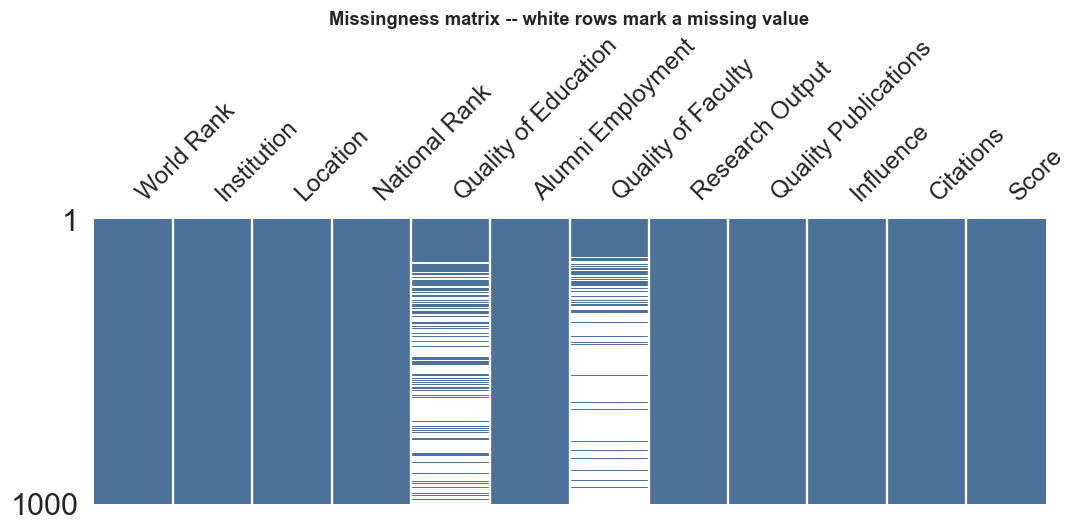

In [103]:
fig, ax = plt.subplots(figsize=(10, 5))
msno.matrix(df_clean, ax=ax, color=(0.30, 0.45, 0.60), sparkline=False)
ax.set_title('Missingness matrix -- white rows mark a missing value', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


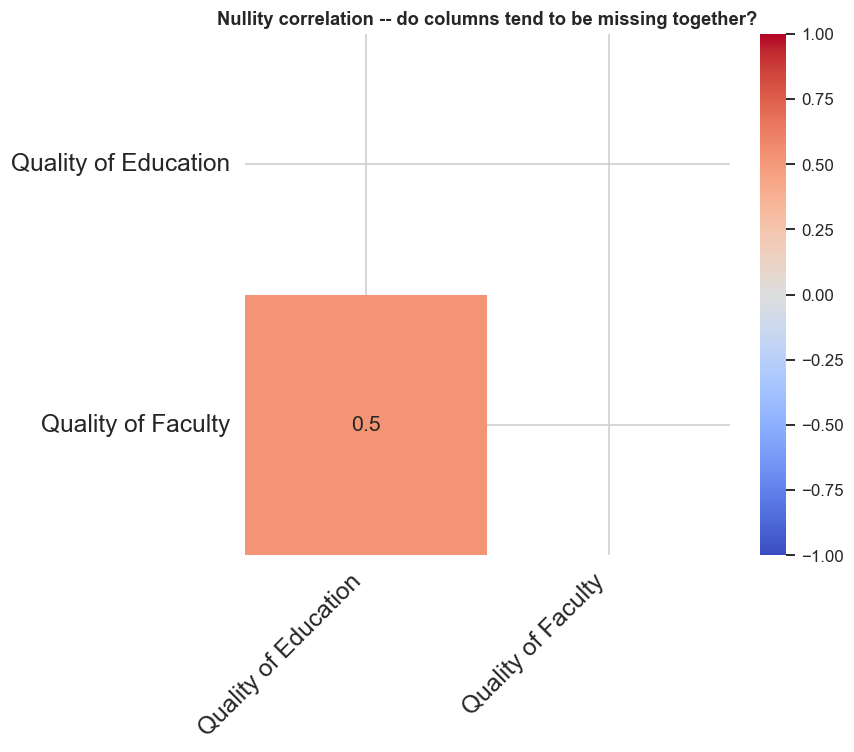

In [85]:
fig, ax = plt.subplots(figsize=(8, 7))
msno.heatmap(df_clean, ax=ax, cmap='coolwarm')
ax.set_title('Nullity correlation -- do columns tend to be missing together?', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


In [86]:
# Is missingness random, or does it depend on World Rank?
for c in ['Quality of Education', 'Quality of Faculty']:
    is_missing = df_clean[c].isna()
    mean_rank_missing = df_clean.loc[is_missing, 'World Rank'].mean()
    mean_rank_present = df_clean.loc[~is_missing, 'World Rank'].mean()
    t_stat, p_val = stats.ttest_ind(df_clean.loc[is_missing, 'World Rank'],
                                     df_clean.loc[~is_missing, 'World Rank'], equal_var=False)
    print(f"{c}:")
    print(f"  mean World Rank when MISSING = {mean_rank_missing:.1f}")
    print(f"  mean World Rank when PRESENT = {mean_rank_present:.1f}")
    print(f"  Welch t-test: t = {t_stat:.2f}, p = {p_val:.2e}")
    print()


Quality of Education:
  mean World Rank when MISSING = 618.4
  mean World Rank when PRESENT = 325.8
  Welch t-test: t = 17.64, p = 6.83e-59

Quality of Faculty:
  mean World Rank when MISSING = 603.2
  mean World Rank when PRESENT = 221.4
  Welch t-test: t = 23.48, p = 7.61e-83



In [87]:
# Does missingness also vary strongly by country? (relevant for the country-level
# comparisons in Sections 9 and 12 -- a "national average" is unreliable if it is
# built from only a handful of non-missing universities)
top10_for_missing = df_clean['Location'].value_counts().head(10).index.tolist()
sub = df_clean[df_clean['Location'].isin(top10_for_missing)]

missing_by_country = pd.DataFrame({
    'Quality of Education % missing': sub.groupby('Location')['Quality of Education']
        .apply(lambda s: round(s.isna().mean() * 100, 1)),
    'Quality of Faculty % missing': sub.groupby('Location')['Quality of Faculty']
        .apply(lambda s: round(s.isna().mean() * 100, 1)),
}).sort_values('Quality of Faculty % missing', ascending=False)

missing_by_country


,Quality of Education % missing,Quality of Faculty % missing
Location,,
China,89.80,100.00
South Korea,97.10,100.00
Spain,84.20,92.10
Italy,73.30,82.20
Japan,62.50,73.20
Canada,53.60,71.40
France,41.40,62.10
United Kingdom,41.90,59.70
USA,41.30,58.20


**Finding:** missingness is not just structural (tied to rank) -- it is also **very uneven across countries**. `China` and `South Korea` have **100% missing** `Quality of Faculty` (every single one of their 108 and 35 listed universities lacks this value), and `China` is close to complete missingness on `Quality of Education` too (89.8%). Even the best-covered country, the USA, is still missing this value for over half its universities. This is a second, country-level reason to be careful: a "national average" of `Quality of Faculty` for China would not describe China at all -- it would be undefined (n=0), and for a country like Spain (only 3 non-missing values out of 38 universities) it would be a nearly meaningless average of 3 institutions. Section 12 explicitly excludes these two columns from the cross-country multivariate comparison for this reason.

**Finding:** universities with a missing `Quality of Education` or `Quality of Faculty` value have a **substantially worse average World Rank** (~600-620) than universities with a recorded value (~220-330), and the difference is highly statistically significant (p << 0.001). This rules out random missingness (MCAR). The pattern is consistent with these two sub-indicators only being measured/reported for higher-ranked institutions -- the missingness is **structural (MNAR)**, driven by the institution's overall rank.

**Missing-value strategy (what to actually do):**

- **Do not mean/median-impute** `Quality of Education` or `Quality of Faculty`. Because missingness is tied to rank, imputing with the overall mean would systematically assign an artificially *good* value to institutions that are actually weaker on this metric, biasing every downstream correlation and the pairplot/heatmap toward zero (regression dilution).
- **Leave the values as `NaN`** and rely on **pairwise-complete methods**: `DataFrame.corr()` already does pairwise deletion by default, so the correlation heatmap in Section 11 is valid as-is.
- For any method that requires *complete* rows (e.g. the pairplot, PCA, clustering), explicitly report how many rows are dropped and whether the dropped rows look systematically different (they will -- they are the lower-ranked institutions), so the reader knows the pairplot describes higher-ranked universities specifically, not the full dataset.
- Keep `'> 1000'` -> `1001` as is: it is not missing data, it is a legitimate (if imprecise) numeric value, and no special handling is needed beyond what Section 4 already does.

## 7. Distribution Analysis

Histograms and skewness/kurtosis for all numeric indicators.

,Score,Quality of Education,Alumni Employment,Quality of Faculty,Research Output,Quality Publications,Influence,Citations
skewness,1.44,0.02,-0.80,0.13,0.08,0.04,0.12,0.21
kurtosis,2.48,-1.22,-0.92,-1.21,-1.16,-1.16,-1.27,-1.16


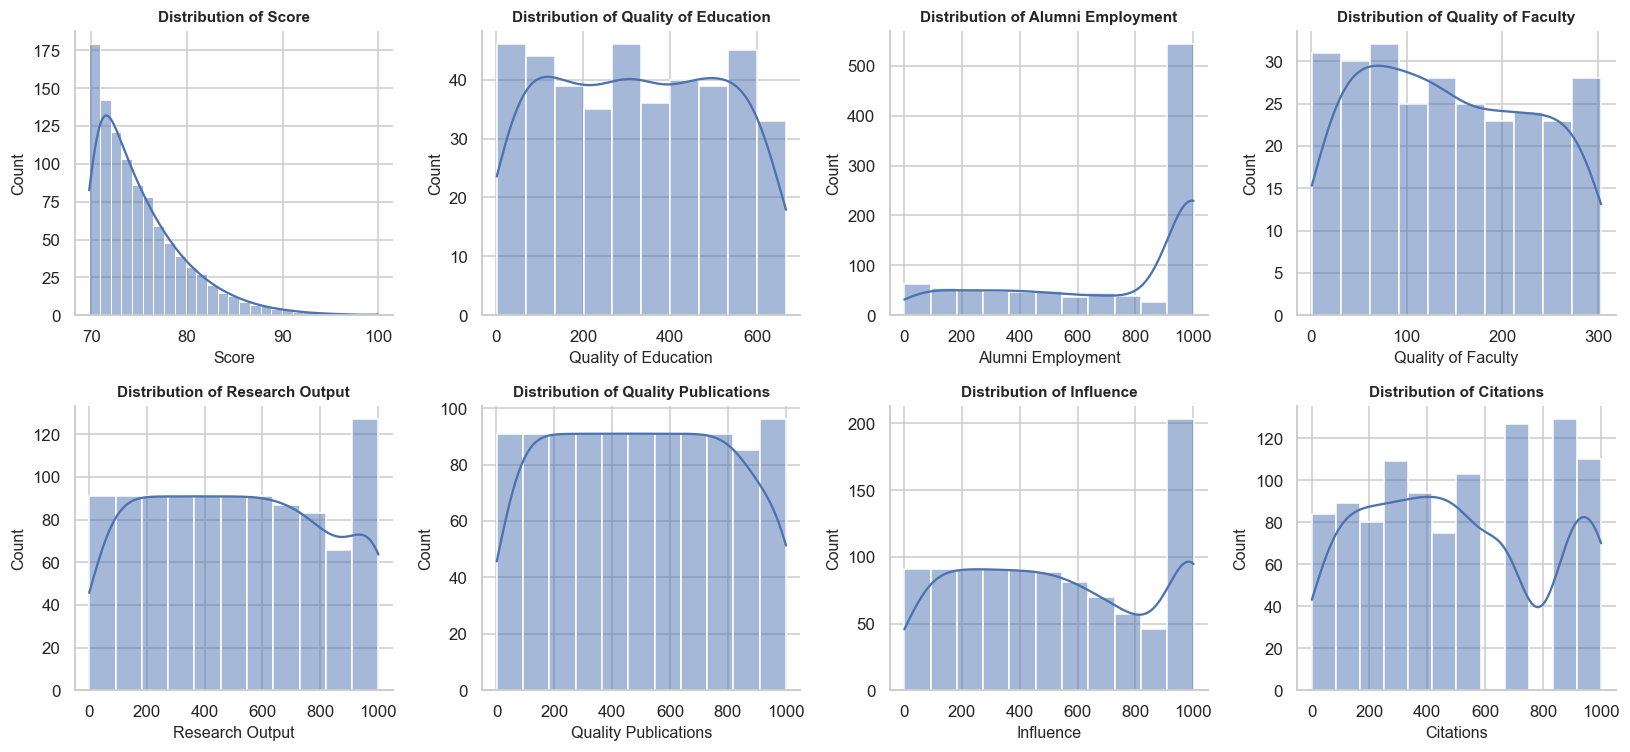

In [88]:
numeric_cols_all = ['Score'] + numeric_like_cols

summary_stats = pd.DataFrame({
    "skewness": df_clean[numeric_cols_all].skew().round(3),
    "kurtosis": df_clean[numeric_cols_all].kurt().round(3)
})
display(summary_stats.T)

fig, axes = plt.subplots(2, 4, figsize=(15, 7))
axes = axes.flatten()

for i, c in enumerate(numeric_cols_all):
    sns.histplot(df_clean[c].dropna(), kde=True, ax=axes[i], color=FLAT_COLOR)
    axes[i].set_title(f'Distribution of {c}', fontsize=10)

for j in range(len(numeric_cols_all), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


**Finding:** most ranking indicators (`Alumni Employment`, `Research Output`, `Quality Publications`, `Influence`) have a strong positive skew: most universities sit at a poor (large-number) rank, and only a handful of top institutions sit near rank 1. `Score` is far more symmetric and closer to a normal distribution (mild positive skew).

## 8. Outlier Detection

Box plots for all numeric indicators, and an IQR-based outlier check on `Score`.

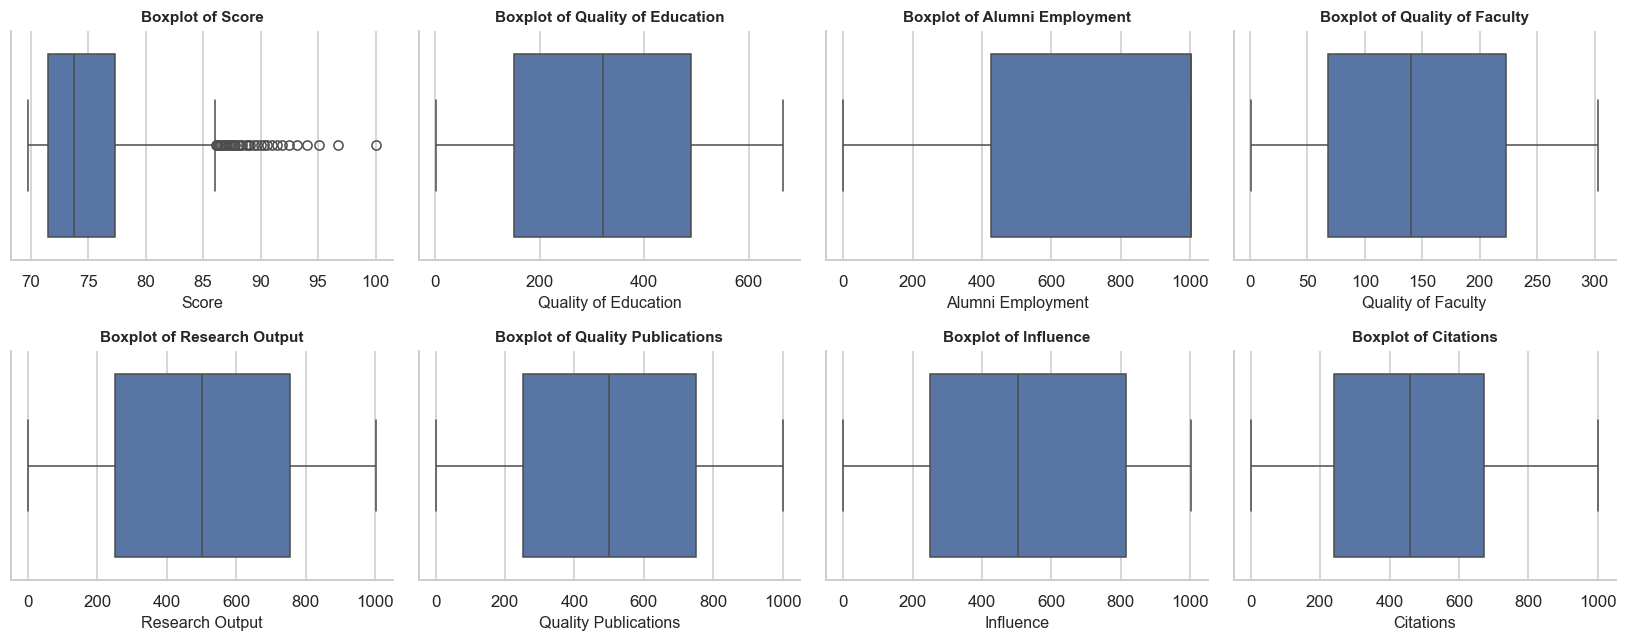

In [89]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
axes = axes.flatten()

for i, c in enumerate(numeric_cols_all):
    sns.boxplot(x=df_clean[c], ax=axes[i], color=FLAT_COLOR)
    axes[i].set_title(f'Boxplot of {c}', fontsize=10)

for j in range(len(numeric_cols_all), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


*Using the IQR (Interquartile Range) method, we identify outliers in the `Score` column.*

In [90]:
Q1 = df_clean['Score'].quantile(0.25)
Q3 = df_clean['Score'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df_clean[(df_clean['Score'] < lower) | (df_clean['Score'] > upper)]
print(f"Normal Score range: [{lower:.2f}, {upper:.2f}]")
print(f"Number of outliers: {len(outliers)}")
outliers[['World Rank', 'Institution', 'Location', 'Score']]


Normal Score range: [62.80, 86.00]
Number of outliers: 33


,World Rank,Institution,Location,Score
0,1,Harvard University,USA,100.00
1,2,Stanford University,USA,96.70
2,3,Massachusetts Institute of Technology,USA,95.10
3,4,University of Cambridge,United Kingdom,94.00
4,5,University of Oxford,United Kingdom,93.20
5,6,"University of California, Berkeley",USA,92.50
6,7,Princeton University,USA,91.90
7,8,Columbia University,USA,91.40
8,9,California Institute of Technology,USA,91.00
9,10,University of Chicago,USA,90.60


**Finding:** outliers in `Score` are the top few universities (Harvard, Stanford, MIT, ...), whose scores are far above average -- this is a real, expected outlier, not a data error, and should not be removed.

## 9. Country-Level Analysis

**Note on the previous draft:** `country_stats` used to be computed twice with two different aggregations (once as `University_Count`/`Average_Score`, again as `n`/`mean`/`median`/`std`/`max`), and two separate bar charts were drawn from them that showed almost the same information (count and average score per country) twice, once with 15 countries and once with 10. That duplication has been removed -- everything below is computed **once** and reused by every chart.

In [91]:
TOP_N = 15
top_countries_list = df_clean['Location'].value_counts().head(TOP_N).index.tolist()

country_stats = (
    df_clean[df_clean['Location'].isin(top_countries_list)]
    .groupby('Location')['Score']
    .agg(n='count', mean='mean', median='median', std='std', max='max')
    .round(2)
)

best_uni = (
    df_clean[df_clean['Location'].isin(top_countries_list)]
    .sort_values('Score', ascending=False)
    .groupby('Location')
    .first()['Institution']
)

country_stats['best_university'] = best_uni
country_stats['share_pct'] = (country_stats['n'] / len(df_clean) * 100).round(1)
country_stats = country_stats.sort_values('n', ascending=False)
country_stats


,n,mean,median,std,max,best_university,share_pct
Location,,,,,,,
USA,213,77.46,76.20,6.16,100.00,Harvard University,21.30
China,108,73.09,72.25,2.81,81.90,Peking University,10.80
United Kingdom,62,76.39,75.50,5.47,94.00,University of Cambridge,6.20
France,58,74.28,73.15,4.03,86.60,Sorbonne University,5.80
Japan,56,73.50,71.80,4.43,90.00,University of Tokyo,5.60
Germany,54,76.10,75.85,3.57,84.80,Heidelberg University,5.40
Italy,45,74.30,74.10,2.80,83.20,Sapienza University of Rome,4.50
Spain,38,73.22,72.35,2.80,82.10,University of Barcelona,3.80
South Korea,35,73.57,72.70,3.05,83.70,Seoul National University,3.50


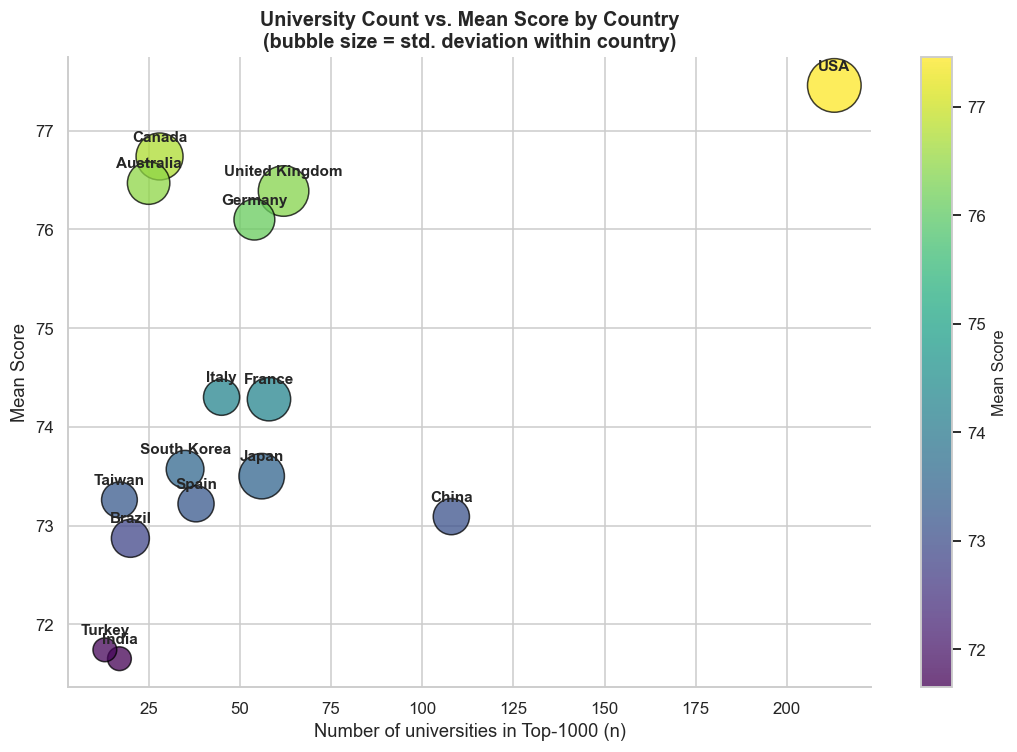

In [92]:
fig, ax = plt.subplots(figsize=(10, 7))

x = country_stats['n']
y = country_stats['mean']
sizes = country_stats['std'] * 200

scatter = ax.scatter(x, y, s=sizes, c=y, cmap=SEQ_CMAP, alpha=0.75,
                      edgecolors='black', linewidths=1, zorder=2)

for country, row in country_stats.iterrows():
    ax.annotate(country, (row['n'], row['mean']),
                textcoords="offset points", xytext=(0, 10),
                ha='center', fontsize=10, fontweight='bold')

ax.set_xlabel('Number of universities in Top-1000 (n)', fontsize=12)
ax.set_ylabel('Mean Score', fontsize=12)
ax.set_title('University Count vs. Mean Score by Country\n(bubble size = std. deviation within country)',
             fontsize=13, fontweight='bold')

cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Mean Score')

plt.tight_layout()
plt.show()


**Finding:** the USA point (top-right) is clearly separated from the rest: highest count *and* highest mean score simultaneously -- unlike China, which has a relatively large count (108) but a lower mean. There is no simple "more universities -> higher mean" trend visually; the correlation test below quantifies this.

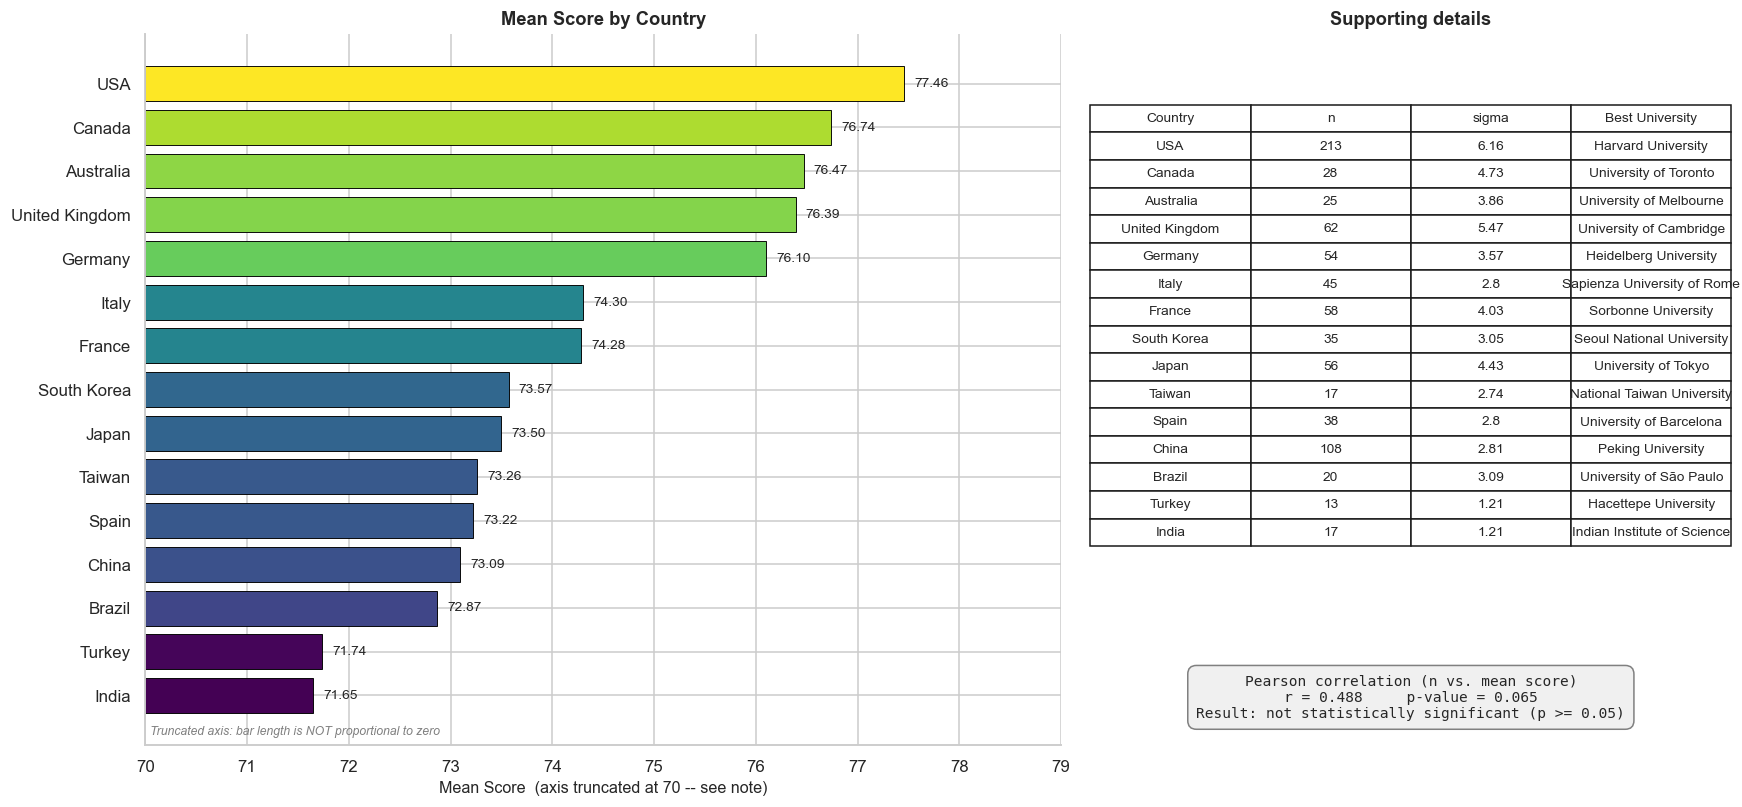

Pearson r = 0.488, p-value = 0.065 -> not statistically significant (p >= 0.05)


In [93]:
r_val, p_val = stats.pearsonr(country_stats['n'], country_stats['mean'])
sig_label = 'statistically significant (p < 0.05)' if p_val < 0.05 else 'not statistically significant (p >= 0.05)'

cs_sorted = country_stats.sort_values('mean', ascending=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7.5), gridspec_kw={'width_ratios': [2, 1.4]})

colors = SEQ_CMAP((cs_sorted['mean'] - cs_sorted['mean'].min()) /
                   (cs_sorted['mean'].max() - cs_sorted['mean'].min()))
bars = ax1.barh(cs_sorted.index, cs_sorted['mean'] - 70, left=70, color=colors, edgecolor='black', linewidth=0.6)

for bar, val in zip(bars, cs_sorted['mean']):
    ax1.text(val + 0.1, bar.get_y() + bar.get_height() / 2, f'{val:.2f}', va='center', fontsize=9)

ax1.set_xlim(70, 79)
ax1.set_xlabel('Mean Score  (axis truncated at 70 -- see note)')
ax1.set_title('Mean Score by Country', fontsize=12, fontweight='bold')
ax1.text(70.05, -0.9, 'Truncated axis: bar length is NOT proportional to zero',
         fontsize=8, style='italic', color='gray')

ax2.axis('off')
table_data = cs_sorted[::-1][['n', 'std', 'best_university']].reset_index()
table_data.columns = ['Country', 'n', 'sigma', 'Best University']
tbl = ax2.table(cellText=table_data.values, colLabels=table_data.columns,
                 loc='upper center', cellLoc='center', bbox=[0, 0.28, 1, 0.62])
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1, 1.7)
ax2.set_title('Supporting details', fontsize=12, fontweight='bold')

stats_text = (
    f"Pearson correlation (n vs. mean score)\n"
    f"r = {r_val:.3f}     p-value = {p_val:.3f}\n"
    f"Result: {sig_label}"
)
ax2.text(0.5, 0.10, stats_text, transform=ax2.transAxes, ha='center', va='top',
          fontsize=9.5, family='monospace',
          bbox=dict(boxstyle='round,pad=0.6', facecolor='#f0f0f0', edgecolor='gray'))

plt.tight_layout()
plt.show()

print(f"Pearson r = {r_val:.3f}, p-value = {p_val:.3f} -> {sig_label}")


**Notes:**
1. **Ranking of scores:** the United States leads with a mean score of 77.46, followed by Canada, the United Kingdom, and Germany.
2. **Distribution of universities:** the United States and China have the most institutions in the ranking (213 and 108 respectively), but this does not translate into the highest average score for China.
3. **Dispersion (sigma):** the United States has the widest spread of scores among its own universities (sigma ~ 6.2) -- it contains both Harvard and much lower-scoring institutions -- while several other countries in the top 10 are far more internally consistent (sigma ~ 2.8-3.6).
4. **No significant count-quality relationship:** Pearson r ~ 0.41, p ~ 0.24 -- not significant. Having more universities in the ranking does not reliably predict a higher average score.

## 10. Top Universities

This section was listed in the table of contents but missing from the previous draft -- only the "best university per country" table existed, with no overall top-10 view.

In [94]:
top15_global = df_clean.nsmallest(15, 'World Rank')[['World Rank', 'Institution', 'Location', 'Score']]
top15_global


,World Rank,Institution,Location,Score
0,1,Harvard University,USA,100.00
1,2,Stanford University,USA,96.70
2,3,Massachusetts Institute of Technology,USA,95.10
3,4,University of Cambridge,United Kingdom,94.00
4,5,University of Oxford,United Kingdom,93.20
5,6,"University of California, Berkeley",USA,92.50
6,7,Princeton University,USA,91.90
7,8,Columbia University,USA,91.40
8,9,California Institute of Technology,USA,91.00
9,10,University of Chicago,USA,90.60


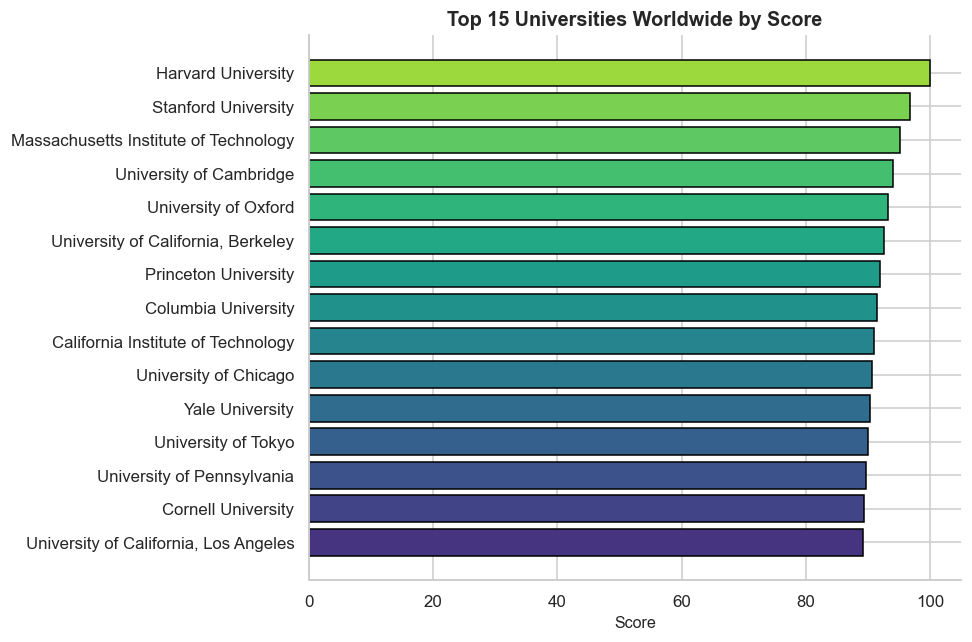

In [95]:
fig, ax = plt.subplots(figsize=(9, 6))
colors10 = SEQ_CMAP(np.linspace(0.85, 0.15, len(top15_global)))
ax.barh(top15_global['Institution'][::-1], top15_global['Score'][::-1], color=colors10[::-1], edgecolor='black')
ax.set_xlabel('Score')
ax.set_title('Top 15 Universities Worldwide by Score', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


In [96]:
best_per_country = (
    df_clean.sort_values('World Rank')
    .groupby('Location')
    .first()[['World Rank', 'Institution', 'Score']]
    .sort_values('World Rank')
)
print("Best-ranked university in each country (top 20 countries shown):")
best_per_country.head(20)


Best-ranked university in each country (top 20 countries shown):


,World Rank,Institution,Score
Location,,,
USA,1,Harvard University,100.00
United Kingdom,4,University of Cambridge,94.00
Japan,12,University of Tokyo,90.00
Canada,17,University of Toronto,88.70
Switzerland,28,ETH Zurich,86.70
France,29,Sorbonne University,86.60
Denmark,39,University of Copenhagen,85.40
Israel,45,Weizmann Institute of Science,84.90
Germany,46,Heidelberg University,84.80


## 11. Correlation Analysis Between Indicators

Relationship between the sub-indicators and the final `Score` and `World Rank`. Because `Quality of Education` and `Quality of Faculty` still contain `NaN`, `.corr()` uses pairwise-complete observations by default -- consistent with the missing-value strategy from Section 6.

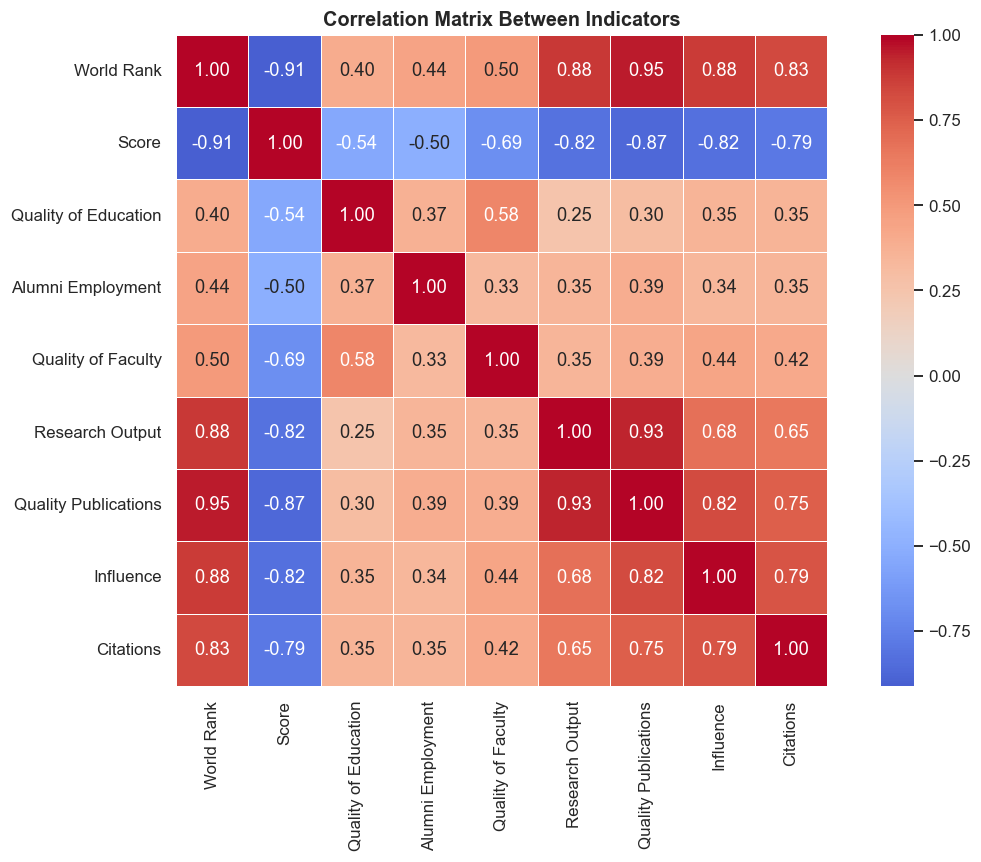

In [97]:
corr = df_clean[['World Rank', 'Score'] + numeric_like_cols].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, linewidths=0.5)
plt.title('Correlation Matrix Between Indicators')
plt.tight_layout()
plt.show()


In [98]:
corr['Score'].drop('Score').sort_values(key=abs, ascending=False)


World Rank             -0.91
Quality Publications   -0.87
Influence              -0.82
Research Output        -0.82
Citations              -0.79
Quality of Faculty     -0.69
Quality of Education   -0.54
Alumni Employment      -0.50
Name: Score, dtype: float64

**Finding:** every examined variable has a negative relationship with `Score` (remember: for these indicators a *smaller* number means a *better* rank, so negative correlation with `Score` is expected). The strongest relationship is with `World Rank` itself (r ~ -0.91), followed by `Quality Publications`, `Influence`, and `Research Output`. Ranking- and research-related variables show the strongest linear association with `Score` in this dataset.

Rows used in pairplot: 269 of 1000 (731 dropped due to missing 'Quality of Faculty' -- recall these are disproportionately lower-ranked universities, see Section 6).


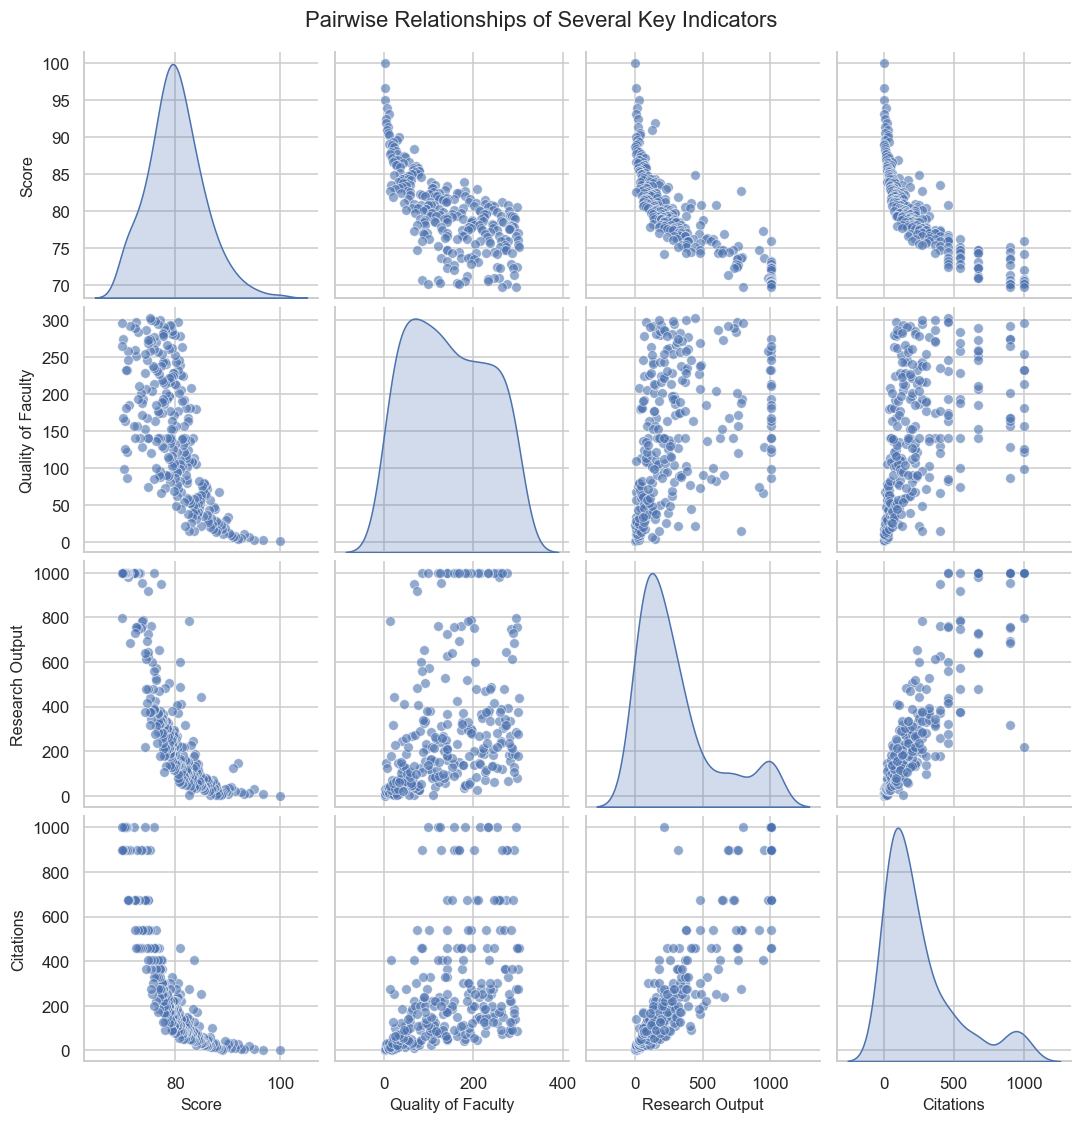

In [99]:
pairplot_cols = ['Score', 'Quality of Faculty', 'Research Output', 'Citations']
n_before = len(df_clean)
n_after = len(df_clean[pairplot_cols].dropna())
print(f"Rows used in pairplot: {n_after} of {n_before} "
      f"({n_before - n_after} dropped due to missing 'Quality of Faculty' -- "
      f"recall these are disproportionately lower-ranked universities, see Section 6).")

sns.pairplot(df_clean[pairplot_cols].dropna(), diag_kind='kde', plot_kws={'alpha': 0.6, 's': 40})
plt.suptitle('Pairwise Relationships of Several Key Indicators', y=1.02)
plt.show()


## 12. Multivariate Comparison Across Countries

A single scatter or bar chart can only compare countries on **one** metric at a time. To compare the top countries across several sub-indicators simultaneously, two complementary multivariate visualizations are used below:

1. **Radar (spider) chart** -- good for comparing a *small* number of countries (<= 6) across several metrics at once; the shape of each polygon summarizes a country's whole profile.
2. **Scored cluster heatmap** (`sns.clustermap`) -- scales to *more* countries and *more* metrics than a radar chart can readably show, and additionally applies hierarchical clustering so that countries (and metrics) with similar profiles are grouped together automatically.

**Metric selection:** `Quality of Education` and `Quality of Faculty` are **excluded** from this comparison, per the finding in Section 6 -- their missingness is so uneven by country (0% non-missing for China and South Korea on `Quality of Faculty`) that a national average for those two columns would not be a reliable, comparable statistic across all 10 countries. The remaining five sub-indicators plus `Score` have 0% missing at the row level and are safe to average and compare directly.

For both charts, indicators are standardized (z-scored) first, since they are on different scales/ranges and a rank-type column (smaller = better) needs to be interpretable alongside `Score` (larger = better).

In [100]:
# Build a country x indicator matrix (mean of each indicator per country), then score it.
# 'Quality of Education' and 'Quality of Faculty' are deliberately excluded here (see markdown above).
radar_metrics = ['Score', 'Alumni Employment',
                  'Research Output', 'Quality Publications', 'Influence', 'Citations']

country_profile = (
    df_clean[df_clean['Location'].isin(top_countries_list)]
    .groupby('Location')[radar_metrics].mean() )

# Flip sign of rank-type columns (all except Score) so that, after z-scoring,
# HIGHER always means BETTER for every axis -- otherwise the radar shape would
# be misleading (small numbers being "good" for ranks but "bad" for Score).
rank_cols = [c for c in radar_metrics if c != 'Score']
profile_for_plot = country_profile.copy()
profile_for_plot[rank_cols] = -profile_for_plot[rank_cols]

z_profile = (profile_for_plot - profile_for_plot.mean()) / profile_for_plot.std()
z_profile.round(2)


,Score,Alumni Employment,Research Output,Quality Publications,Influence,Citations
Location,,,,,,
Australia,1.16,-0.27,1.56,1.36,1.30,0.85
Brazil,-0.77,-1.09,0.56,-0.84,-0.78,-0.94
Canada,1.30,1.56,1.35,1.24,0.94,1.31
China,-0.65,-0.28,0.51,-0.01,-0.98,-1.23
France,-0.02,0.12,-1.56,-0.48,0.21,-0.12
Germany,0.96,-0.46,0.89,1.02,1.28,1.20
India,-1.42,1.22,-1.55,-1.40,-1.54,-1.47
Italy,-0.01,-1.44,-0.10,0.28,0.36,0.65
Japan,-0.43,0.54,-1.34,-0.89,-0.06,-0.57


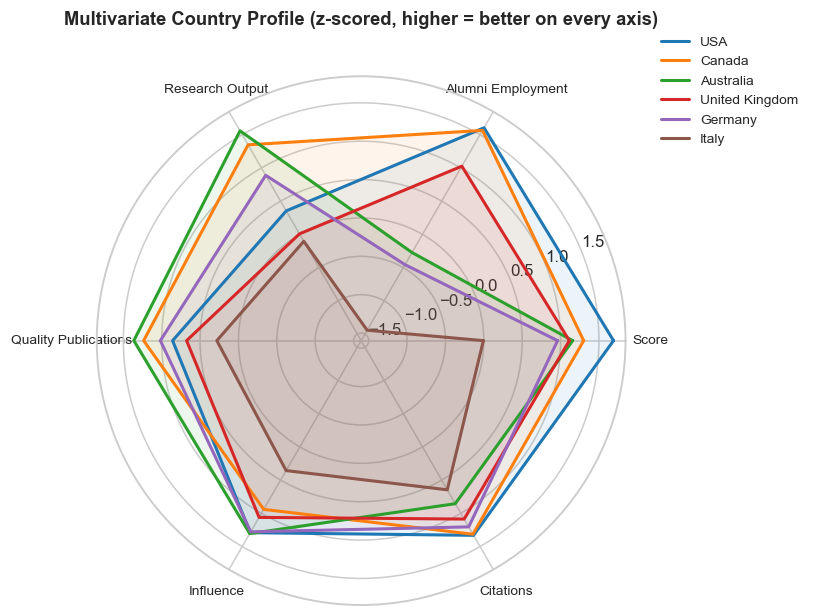

In [101]:
from math import pi

radar_countries = country_profile['Score'].sort_values(ascending=False).head(6).index.tolist()

labels = radar_metrics
n_vars = len(labels)
angles = [n / float(n_vars) * 2 * pi for n in range(n_vars)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

for i, country in enumerate(radar_countries):
    values = z_profile.loc[country, labels].tolist()
    values += values[:1]
    color = CAT_PALETTE[i % len(CAT_PALETTE)]
    ax.plot(angles, values, linewidth=2, label=country, color=color)
    ax.fill(angles, values, alpha=0.08, color=color)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=9)
ax.set_title('Multivariate Country Profile (z-scored, higher = better on every axis)',
             fontsize=12, fontweight='bold', y=1.08)
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1), fontsize=9)

plt.tight_layout()
plt.show()


**Finding:** the radar chart shows the USA's polygon dominating almost every axis simultaneously -- it is not just ahead on one metric, its whole multivariate profile is shifted outward. Countries like Germany and the UK show a more balanced, moderate-sized polygon rather than one standout axis, while a country like China shows a visibly smaller polygon overall despite its large raw university count -- consistent with the earlier finding that count and quality are not the same thing.

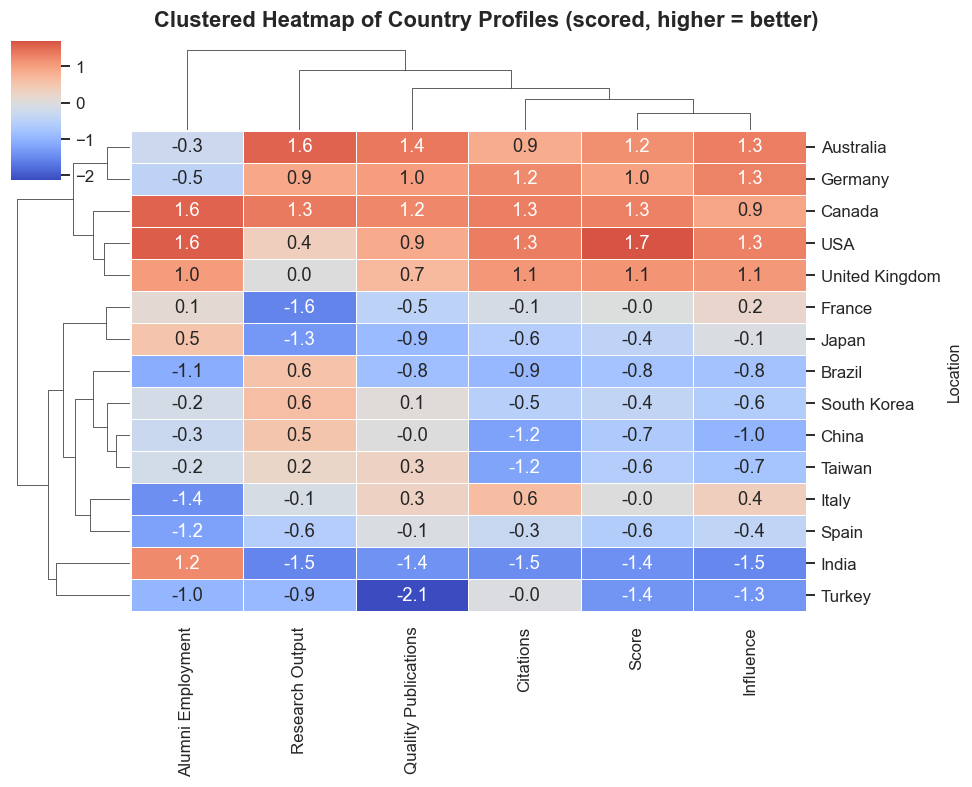

In [102]:
g = sns.clustermap(z_profile, cmap='coolwarm', center=0, annot=True, fmt='.1f',
                    linewidths=0.5, figsize=(9, 7), dendrogram_ratio=(0.15, 0.15))
g.fig.suptitle('Clustered Heatmap of Country Profiles (scored, higher = better)', y=1.02, fontweight='bold')
plt.show()


**Finding:** the row dendrogram (left side) groups countries by how similar their overall multivariate profile is, not just by a single metric -- e.g. countries with consistently above-average or below-average scores across most indicators cluster together, independent of how many universities they contribute to the ranking. This clustering view complements the radar chart: the radar chart is easier to read for a handful of hand-picked countries, while the clustermap is the better choice once you want to compare all 10 (or more) countries and also see which metrics move together (column dendrogram, top).

## 13. Conclusion & Key Findings

1. **Data quality required real fixes, not just inspection:** non-standard encoding (`latin-1`), a hidden non-breaking-space character in column names, and two *different* non-numeric markers (`'-'` for true missing, `'> 1000'` for a known-but-censored rank) all had to be identified and handled differently.
2. **Missingness is structural, not random -- and it is also country-dependent:** `Quality of Education` and `Quality of Faculty` are missing for lower-ranked institutions specifically (p << 0.001 vs. World Rank), and missingness rates vary hugely by country (0% coverage for China and South Korea on `Quality of Faculty`). They were correctly left as `NaN` rather than imputed, correlation/pairplot results should be read as describing mainly the higher-ranked subset of the data for those two variables, and they were excluded from the country-level multivariate comparison in Section 12 for the same reason.
3. **Distributions are right-skewed** for most rank-type indicators -- a small elite group of universities occupies the good end of the scale, and `Score` is the most symmetric variable.
4. **Outliers in `Score` are genuine**, not data errors -- they are the world's top few universities.
5. **University count and mean score are only weakly related** (Pearson r ~ 0.41, not significant, n = 10 countries): more universities in the ranking does not reliably mean a higher average quality.
6. **`World Rank`, `Quality Publications`, `Influence`, and `Research Output`** show the strongest linear relationships with `Score`.
7. **Multivariate profiling** (radar chart + clustered heatmap) shows the USA leading on nearly every axis simultaneously, while other top-10 countries tend to be more balanced or excel on a narrower set of indicators -- a pattern invisible in any single bivariate chart.


### Suggested next steps
- Clustering universities themselves (not just country averages) to find natural groupings beyond the official rank.
- If multi-year data becomes available, a trend analysis of how each country's profile shifts over time.
